<center><h1>Gong_Jiale_HW8</h1></center>

Name: Jialegong
<br>
Github Username: Jialegong
<br>
USC ID: 1387502580

## 1. Supervised, Semi-Supervised, and Unsupervised Learning

Import packages

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from sklearn.model_selection import (train_test_split,GridSearchCV,StratifiedKFold)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC, SVC
from sklearn.cluster import KMeans, SpectralClustering
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,roc_curve,confusion_matrix)
from sklearn.exceptions import ConvergenceWarning

### (a) Download the Breast Cancer Wisconsin (Diagnostic) Data Set

In [7]:
URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/breast-cancer-wisconsin/wdbc.data"
columns = ["id", "diagnosis"] + [f"x{i}" for i in range(1, 31)]
df = pd.read_csv(URL, header=None, names=columns)
X = df.iloc[:, 2:].values.astype(float)
y = (df["diagnosis"] == "M").astype(int).values
print("X shape:", X.shape)
print("y shape:", y.shape)
print("Class counts (B=0, M=1):", np.bincount(y))

X shape: (569, 30)
y shape: (569,)
Class counts (B=0, M=1): [357 212]


### (b) Monte-Carlo Simulation

#### (i) Supervised Learning

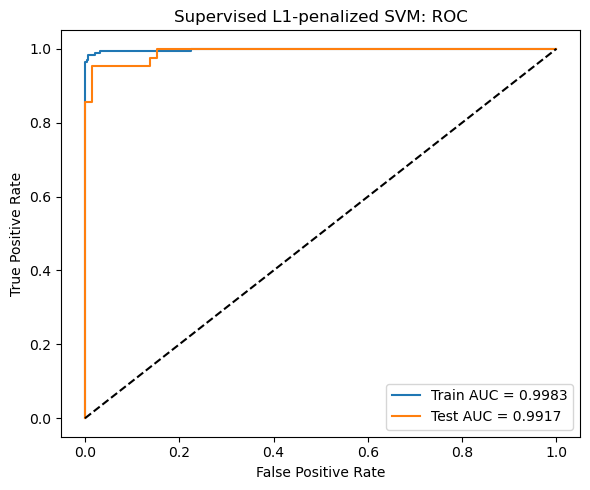

Selected C in the first run: 0.5336699231206307
Training confusion matrix (rows=true, cols=pred):
[[283   2]
 [  5 165]]
Test confusion matrix (rows=true, cols=pred):
[[71  1]
 [ 4 38]]
Average metrics over 30 runs:
train_accuracy     0.986081
train_precision    0.992988
train_recall       0.969608
train_f1           0.981125
train_auc          0.996954
test_accuracy      0.970175
test_precision     0.974432
test_recall        0.944444
test_f1            0.958710
test_auc           0.993739
dtype: float64


In [10]:
RANDOM_STATE = 42
M = 30  
def compute_metrics(y_true, y_pred, scores):
    return dict(accuracy=accuracy_score(y_true, y_pred),
                precision=precision_score(y_true, y_pred, zero_division=0),
                recall=recall_score(y_true, y_pred, zero_division=0),
                f1=f1_score(y_true, y_pred, zero_division=0),
                auc=roc_auc_score(y_true, scores))

def make_l1_svm_cv():
    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", LinearSVC(
            penalty="l1",
            dual=False,
            loss="squared_hinge",
            C=1.0,
            max_iter=100000,  
            tol=1e-3,         
            random_state=RANDOM_STATE
        ))
    ])

    Cs = np.logspace(-3, 2, 12)

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=RANDOM_STATE
    )

    return GridSearchCV(
        pipeline,
        param_grid={"svm__C": Cs},
        cv=cv,
        scoring="accuracy",
        n_jobs=-1
    )

all_results = []

for run in range(M):
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, stratify=y,
        random_state=RANDOM_STATE + run
    )

    clf = make_l1_svm_cv()
    clf.fit(X_train, y_train)

    y_train_pred = clf.predict(X_train)
    y_test_pred = clf.predict(X_test)
    train_scores = clf.decision_function(X_train)
    test_scores = clf.decision_function(X_test)
    train_metrics = compute_metrics(y_train, y_train_pred, train_scores)
    test_metrics = compute_metrics(y_test, y_test_pred, test_scores)

    row = {}
    for k, v in train_metrics.items():
        row[f"train_{k}"] = v
    for k, v in test_metrics.items():
        row[f"test_{k}"] = v
    row["selected_C"] = clf.best_params_["svm__C"]
    all_results.append(row)

    if run == 0:
        fpr_train, tpr_train, _ = roc_curve(y_train, train_scores)
        fpr_test, tpr_test, _ = roc_curve(y_test, test_scores)

        plt.figure(figsize=(6, 5))
        plt.plot(fpr_train, tpr_train,
                 label=f"Train AUC = {train_metrics['auc']:.4f}")
        plt.plot(fpr_test, tpr_test,
                 label=f"Test AUC = {test_metrics['auc']:.4f}")
        plt.plot([0, 1], [0, 1], "k--")
        plt.xlabel("False Positive Rate")
        plt.ylabel("True Positive Rate")
        plt.title("Supervised L1-penalized SVM: ROC")
        plt.legend()
        plt.tight_layout()
        plt.show()

        print("Selected C in the first run:", clf.best_params_["svm__C"])
        print("Training confusion matrix (rows=true, cols=pred):")
        print(confusion_matrix(y_train, y_train_pred, labels=[0, 1]))
        print("Test confusion matrix (rows=true, cols=pred):")
        print(confusion_matrix(y_test, y_test_pred, labels=[0, 1]))

results_df = pd.DataFrame(all_results)
average_metrics = results_df.drop(columns=["selected_C"]).mean()
print("Average metrics over", M, "runs:")
print(average_metrics)

results_df.to_csv("supervised_l1_svm_all_runs.csv", index=False)
average_metrics.to_csv("supervised_l1_svm_average_metrics.csv")

#### (ii) Semi-Supervised Learning/ Self-training

##### (A)

In [13]:
def prepare_labels(run):
    X_pool, X_test, y_pool, y_test = train_test_split(
        X, y, test_size=0.2, stratify=y,
        random_state=RANDOM_STATE + run
    )

    idx_pos = np.where(y_pool == 1)[0]
    idx_neg = np.where(y_pool == 0)[0]

    rng = np.random.RandomState(RANDOM_STATE + 1000 + run)
    rng.shuffle(idx_pos)
    rng.shuffle(idx_neg)

    n_pos_lab = len(idx_pos) // 2
    n_neg_lab = len(idx_neg) // 2

    lab_idx = np.concatenate([idx_pos[:n_pos_lab], idx_neg[:n_neg_lab]])
    unl_idx = np.concatenate([idx_pos[n_pos_lab:], idx_neg[n_neg_lab:]])

    return (X_pool, y_pool, X_test, y_test,
            X_pool[lab_idx].copy(), y_pool[lab_idx].copy(),
            X_pool[unl_idx].copy())

(X_pool, y_pool, X_test, y_test,
 X_lab, y_lab, X_unl) = prepare_labels(run=0)

clf = make_l1_svm_cv()
clf.fit(X_lab, y_lab)

print("Selected C (5-fold CV):", clf.best_params_["svm__C"])
print("Labeled samples:", len(X_lab), "| Unlabeled samples:", len(X_unl))

Selected C (5-fold CV): 0.0657933224657568
Labeled samples: 227 | Unlabeled samples: 228


##### (B)

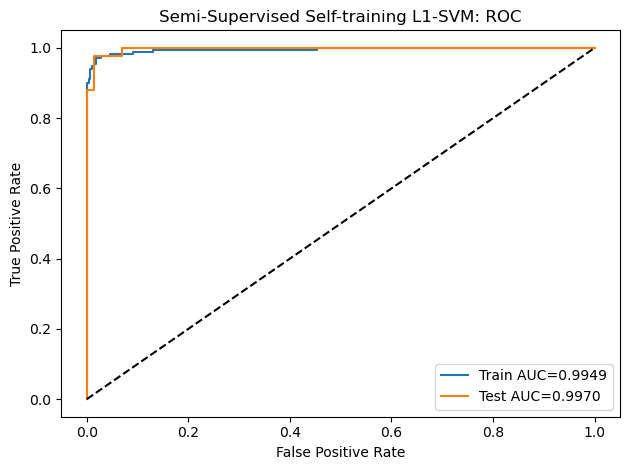

Selected C: 0.0657933224657568
Training confusion matrix: [[282   3]
 [ 10 160]]
Test confusion matrix: [[71  1]
 [ 3 39]]
Average metrics over 30 runs:
train_accuracy     0.974359
train_precision    0.980715
train_recall       0.950392
train_f1           0.965129
train_auc          0.994446
test_accuracy      0.967544
test_precision     0.966222
test_recall        0.946032
test_f1            0.955537
test_auc           0.991788
dtype: float64


In [15]:
results = []
for run in range(M):
    X_pool, y_pool, X_test, y_test, X_lab, y_lab, X_unl = prepare_labels(run)
    initial_clf = make_l1_svm_cv()
    initial_clf.fit(X_lab, y_lab)
    C = initial_clf.best_params_["svm__C"]
    best = initial_clf.best_estimator_
    while len(X_unl) > 0:
        best.set_params(svm__C=C)
        best.fit(X_lab, y_lab)
        scores_unl = best.decision_function(X_unl)
        i = int(np.argmax(np.abs(scores_unl)))
        pseudo_label = best.predict(X_unl[[i]])[0]
        X_lab = np.vstack([X_lab, X_unl[i]])
        y_lab = np.append(y_lab, pseudo_label)
        X_unl = np.delete(X_unl, i, axis=0)
    best.set_params(svm__C=C)
    best.fit(X_lab, y_lab)

    tr = compute_metrics(y_pool, best.predict(X_pool), best.decision_function(X_pool))
    te = compute_metrics(y_test, best.predict(X_test), best.decision_function(X_test))

    results.append({**{f"train_{k}": v for k, v in tr.items()},
                    **{f"test_{k}": v for k, v in te.items()}})

    if run == 0:
        for name, yt in [("Train", y_pool), ("Test", y_test)]:
            sc = best.decision_function(
                X_pool if name == "Train" else X_test)
            fpr, tpr, _ = roc_curve(yt, sc)
            plt.plot(fpr, tpr, label=f"{name} AUC={roc_auc_score(yt, sc):.4f}")
        plt.plot([0, 1], [0, 1], "k--")
        plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
        plt.title("Semi-Supervised Self-training L1-SVM: ROC")
        plt.legend(); plt.tight_layout(); plt.show()

        print("Selected C:", C)
        print("Training confusion matrix:",
              confusion_matrix(y_pool, best.predict(X_pool), labels=[0, 1]))
        print("Test confusion matrix:",
              confusion_matrix(y_test, best.predict(X_test), labels=[0, 1]))

res_df = pd.DataFrame(results)
avg = res_df.mean()
print("Average metrics over", M, "runs:")
print(avg)

res_df.to_csv("semi_supervised_selftraining_all_runs.csv", index=False)
avg.to_csv("semi_supervised_selftraining_average_metrics.csv")

#### (iii) Unsupervised Learning

##### (A)

In [18]:
M = 30
km_runs = []
for run in range(M):
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=0.2, stratify=y,
        random_state=RANDOM_STATE + run
    )
    scaler = StandardScaler().fit(X_tr)
    X_tr_s = scaler.transform(X_tr)
    X_te_s = scaler.transform(X_te)

    km = KMeans(
        n_clusters=2,
        init="random",
        n_init=30,
        max_iter=300,
        random_state=RANDOM_STATE + 1000 + run
    )
    km.fit(X_tr_s)

    km_runs.append({
        "model": km,
        "X_train_s": X_tr_s,
        "X_test_s": X_te_s,
        "y_train": y_tr,
        "y_test": y_te
    })
    if run == 0:
        print("First-run inertia:", km.inertia_)
        print("First-run cluster sizes:", np.bincount(km.labels_))
        print("Cluster centers shape:", km.cluster_centers_.shape)

print("Completed Monte Carlo runs:", len(km_runs))

First-run inertia: 9254.827299171
First-run cluster sizes: [158 297]
Cluster centers shape: (2, 30)
Completed Monte Carlo runs: 30


For each training split, I ran K-means with 30 random initializations using `init="random"` and `n_init=30`. The solution with the smallest inertia, defined as the within-cluster sum of squared distances, was retained. Multiple initializations reduce the risk of selecting a poor local minimum, although they do not guarantee the global minimum. The entire procedure was repeated over 30 random stratified train-test splits.

##### (B)

First-run cluster labels: [1 0]
Training confusion matrix (rows=true, cols=pred):
[[270  15]
 [ 27 143]]


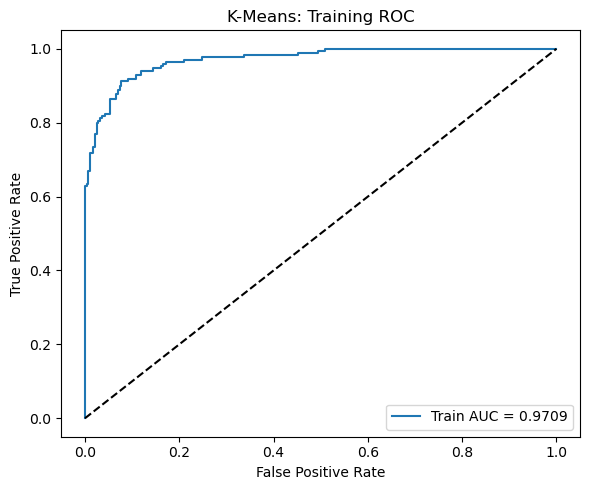

Average training metrics over 30 runs:
train_accuracy     0.909963
train_precision    0.924540
train_recall       0.827059
train_f1           0.872820
train_auc          0.974661
dtype: float64


In [21]:
def kmeans_positive_score(dist, cluster_label):
    logits = -dist
    logits -= logits.max(axis=1, keepdims=True)
    prob = np.exp(logits)
    prob /= prob.sum(axis=1, keepdims=True)
    return prob @ cluster_label


km_train_results = []

for run, item in enumerate(km_runs):
    km = item["model"]
    y_tr = item["y_train"]
    dist_tr = km.transform(item["X_train_s"])

    cluster_label = np.zeros(2, dtype=int)

    for c in range(2):
        nearest30 = np.argsort(dist_tr[:, c])[:30]
        cluster_label[c] = np.bincount(
            y_tr[nearest30], minlength=2
        ).argmax()

    pred_tr = cluster_label[km.labels_]
    score_tr = kmeans_positive_score(dist_tr, cluster_label)

    km_train_results.append(
        compute_metrics(y_tr, pred_tr, score_tr)
    )

    # Save the training-derived labels for part (C)
    item["cluster_label"] = cluster_label

    if run == 0:
        print("First-run cluster labels:", cluster_label)
        print("Training confusion matrix (rows=true, cols=pred):")
        print(confusion_matrix(y_tr, pred_tr, labels=[0, 1]))

        fpr, tpr, _ = roc_curve(y_tr, score_tr)

        plt.figure(figsize=(6, 5))
        plt.plot(
            fpr, tpr,
            label=f"Train AUC = {roc_auc_score(y_tr, score_tr):.4f}"
        )
        plt.plot([0, 1], [0, 1], "k--")
        plt.xlabel("False Positive Rate")
        plt.ylabel("True Positive Rate")
        plt.title("K-Means: Training ROC")
        plt.legend()
        plt.tight_layout()
        plt.show()

km_train_df = pd.DataFrame(km_train_results).add_prefix("train_")

print("Average training metrics over", M, "runs:")
print(km_train_df.mean())

##### (C)

Test confusion matrix (rows=true, cols=pred):
[[69  3]
 [ 9 33]]


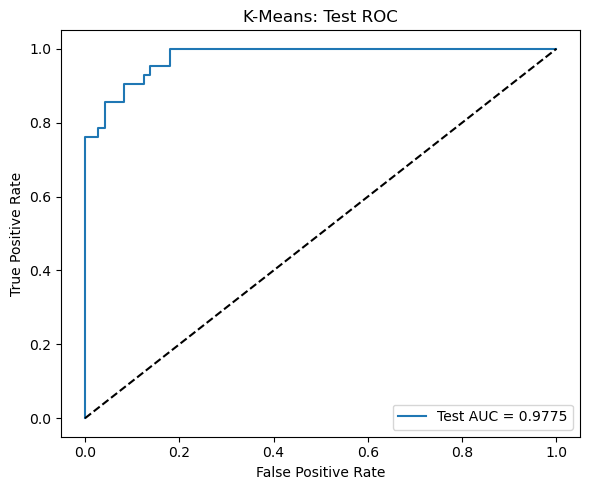

Average test metrics over 30 runs:
test_accuracy     0.913450
test_precision    0.919923
test_recall       0.838889
test_f1           0.876421
test_auc          0.975220
dtype: float64


In [23]:
km_test_results = []
for run, item in enumerate(km_runs):
    km = item["model"]
    y_te = item["y_test"]
    cluster_label = item["cluster_label"]

    cluster_te = km.predict(item["X_test_s"])
    pred_te = cluster_label[cluster_te]

    dist_te = km.transform(item["X_test_s"])
    score_te = kmeans_positive_score(dist_te, cluster_label)

    km_test_results.append(
        compute_metrics(y_te, pred_te, score_te)
    )

    if run == 0:
        print("Test confusion matrix (rows=true, cols=pred):")
        print(confusion_matrix(y_te, pred_te, labels=[0, 1]))

        fpr, tpr, _ = roc_curve(y_te, score_te)

        plt.figure(figsize=(6, 5))
        plt.plot(
            fpr, tpr,
            label=f"Test AUC = {roc_auc_score(y_te, score_te):.4f}"
        )
        plt.plot([0, 1], [0, 1], "k--")
        plt.xlabel("False Positive Rate")
        plt.ylabel("True Positive Rate")
        plt.title("K-Means: Test ROC")
        plt.legend()
        plt.tight_layout()
        plt.show()

km_test_df = pd.DataFrame(km_test_results).add_prefix("test_")

print("Average test metrics over", M, "runs:")
print(km_test_df.mean())

km_results_df = pd.concat([km_train_df, km_test_df], axis=1)
km_average_metrics = km_results_df.mean()

km_results_df.to_csv("kmeans_all_runs.csv", index=False)
km_average_metrics.to_csv("kmeans_average_metrics.csv")

#### (iv) Spectral Clustering

Spectral clustering constructs a similarity graph using an RBF kernel and uses eigenvectors of the normalized graph Laplacian to obtain a lower-dimensional representation. Clustering is then performed in this representation, allowing the method to identify non-convex clusters. In this experiment, I used two clusters, an RBF kernel with gamma = 1, and `fit_predict` on each training set.

Each cluster was assigned a class by majority voting over its training members. Since scikit-learn’s `SpectralClustering` does not provide a prediction method for unseen samples, I used a 5-nearest-neighbor classifier trained on the training cluster assignments as an out-of-sample extension. Test scores were computed by weighting the predicted cluster probabilities by the malignant-class proportions estimated from the training clusters. Test labels were used only for evaluation.

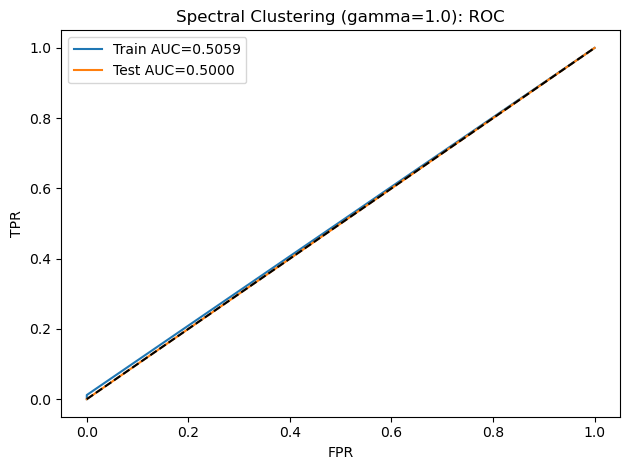

Cluster sizes: [453   2]
Cluster -> label: {0: 0, 1: 1}
Cluster positive ratios: {0: 0.3708609271523179, 1: 1.0}
Train CM: [[285   0]
 [168   2]]
Test CM: [[72  0]
 [42  0]]
Average over 30 runs: train_accuracy     0.629377
train_precision    0.800000
train_recall       0.008039
train_f1           0.015907
train_auc          0.504370
test_accuracy      0.631579
test_precision     0.000000
test_recall        0.000000
test_f1            0.000000
test_auc           0.502778
dtype: float64


In [26]:
GAMMA = 1.0
spectral_results = []
for run in range(M):
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, stratify=y,
        random_state=RANDOM_STATE + run)
    scaler = StandardScaler().fit(X_train)
    X_train_s = scaler.transform(X_train)
    X_test_s = scaler.transform(X_test)

    sc = SpectralClustering(
        n_clusters=2, affinity="rbf", gamma=GAMMA,
        assign_labels="kmeans",
        random_state=RANDOM_STATE + 1000 + run,
        n_init=10
    )
    cluster_train = sc.fit_predict(X_train_s)
    cluster_label, cluster_pos_ratio = {}, {}
    for c in np.unique(cluster_train):
        ratio = y_train[cluster_train == c].mean()
        cluster_pos_ratio[c] = ratio
        cluster_label[c] = int(ratio >= 0.5)
    pred_train = np.array([cluster_label[c] for c in cluster_train])
    score_train = np.array([cluster_pos_ratio[c] for c in cluster_train])
    knn = KNeighborsClassifier(n_neighbors=5).fit(X_train_s, cluster_train)
    proba_test = knn.predict_proba(X_test_s)
    cluster_test = knn.predict(X_test_s)
    pred_test = np.array([cluster_label[c] for c in cluster_test])
    score_test = np.zeros(len(X_test))
    for i, c in enumerate(knn.classes_):
        score_test += proba_test[:, i] * cluster_pos_ratio[c]
    tr = compute_metrics(y_train, pred_train, score_train)
    te = compute_metrics(y_test, pred_test, score_test)
    spectral_results.append({
    **{f"train_{k}": v for k, v in tr.items()},
    **{f"test_{k}": v for k, v in te.items()}
})
    if run == 0:
        for name, yt, sc_ in [("Train", y_train, score_train),
                              ("Test", y_test, score_test)]:
            fpr, tpr, _ = roc_curve(yt, sc_)
            plt.plot(fpr, tpr, label=f"{name} AUC={roc_auc_score(yt, sc_):.4f}")
        plt.plot([0, 1], [0, 1], "k--")
        plt.xlabel("FPR"); plt.ylabel("TPR")
        plt.title(f"Spectral Clustering (gamma={GAMMA}): ROC")
        plt.legend(); plt.tight_layout(); plt.show()
        print("Cluster sizes:", np.bincount(cluster_train))
        print("Cluster -> label:", cluster_label)
        print("Cluster positive ratios:", cluster_pos_ratio)
        print("Train CM:", confusion_matrix(y_train, pred_train, labels=[0, 1]))
        print("Test CM:", confusion_matrix(y_test, pred_test, labels=[0, 1]))
res_df = pd.DataFrame(spectral_results)
avg = res_df.mean()
print("Average over", M, "runs:", avg)
res_df.to_csv("spectral_all_runs.csv", index=False)
avg.to_csv("spectral_average_metrics.csv")

#### (v) Compare

Spectral clustering with gamma = 1 performed poorly, with average test accuracy of 0.6316, F1 of 0, and AUC of 0.5028. The illustrated run produced highly imbalanced clusters and failed to identify malignant test cases. These results reflect the limitations of the chosen gamma and the 5-nearest-neighbor prediction extension. Overall, supervised learning performed best on most test metrics, self-training remained competitive, and both clustering-based approaches performed worse under the chosen settings.

## 2. Active Learning Using Support Vector Machines

### (a) Download the banknote authentication Data Set

In [31]:
url = ("https://archive.ics.uci.edu/ml/machine-learning-databases/00267/data_banknote_authentication.txt")
banknote = pd.read_csv(url, header=None,
    names=["variance", "skewness", "curtosis", "entropy", "class"])
X_bank = banknote.iloc[:, :-1].to_numpy()
y_bank = banknote["class"].to_numpy()
X_train2, X_test2, y_train2, y_test2 = train_test_split(
    X_bank, y_bank, test_size=472, random_state=42)
print("Training set:", X_train2.shape, y_train2.shape)
print("Test set:", X_test2.shape, y_test2.shape)

Training set: (900, 4) (900,)
Test set: (472, 4) (472,)


### (b) Repeat each of the following two procedures 50 times

#### (i) Passive

In [34]:
N_REPEATS = 50
STEP = 10
TOTAL = len(X_train2)
sizes = np.arange(STEP, TOTAL + 1, STEP)
def fit_svm_cv(X, y, seed):
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", LinearSVC(
            penalty="l1", dual=False,
            tol=1e-3, max_iter=100000,
            random_state=seed
        ))
    ])

    cv = StratifiedKFold(
        n_splits=5, shuffle=True, random_state=seed
    )
    grid = GridSearchCV(
        pipe, {"svm__C": np.logspace(-3, 2, 8)},
        cv=cv, scoring="accuracy", n_jobs=1
    )

    with warnings.catch_warnings():
        warnings.filterwarnings(
            "ignore", message="The least populated class in y"
        )
        grid.fit(X, y)

    return grid.best_estimator_
errors_passive = np.zeros((N_REPEATS, len(sizes)))
for rep in range(N_REPEATS):
    rng = np.random.RandomState(RANDOM_STATE + rep)
    while True:
        order = rng.permutation(TOTAL)
        counts = np.bincount(y_train2[order[:STEP]], minlength=2)
        if counts.min() >= 2:
            break

    for i, n in enumerate(sizes):
        idx = order[:n]
        clf = fit_svm_cv(
            X_train2[idx], y_train2[idx],
            seed=RANDOM_STATE + rep * 1000 + i
        )
        errors_passive[rep, i] = 1 - clf.score(X_test2, y_test2)
print("Passive test-error matrix shape:", errors_passive.shape)
np.save("errors_passive.npy", errors_passive)

Passive test-error matrix shape: (50, 90)


#### (ii) Active

In [36]:
def distance_to_hyperplane(clf, X_unscaled):
    return np.abs(clf.decision_function(X_unscaled))

errors_active = np.zeros((N_REPEATS, len(sizes)))

for rep in range(N_REPEATS):
    rng = np.random.RandomState(RANDOM_STATE + rep)

    while True:
        order = rng.permutation(TOTAL)
        counts = np.bincount(y_train2[order[:STEP]], minlength=2)
        if counts.min() >= 2:
            break

    labeled_idx = list(order[:STEP])
    unlabeled_idx = list(order[STEP:])
    unlabeled_idx = np.array(unlabeled_idx)

    for i, n in enumerate(sizes):
        clf = fit_svm_cv(
            X_train2[labeled_idx], y_train2[labeled_idx],
            seed=RANDOM_STATE + rep * 1000 + i
        )
        errors_active[rep, i] = 1.0 - accuracy_score(
            y_test2, clf.predict(X_test2)
        )

        if i < len(sizes) - 1 and len(unlabeled_idx) > 0:
            dist = distance_to_hyperplane(
                clf, X_train2[unlabeled_idx]
            )
            k = min(STEP, len(unlabeled_idx))
            nearest_local = np.argsort(dist)[:k]

            chosen = unlabeled_idx[nearest_local]
            labeled_idx = list(labeled_idx) + list(chosen)
            unlabeled_idx = np.delete(unlabeled_idx, nearest_local)

print("Active test-error matrix shape:", errors_active.shape)
np.save("errors_active.npy", errors_active)

Active test-error matrix shape: (50, 90)


### (c) Average the 50 test errors

Passive shape: (50, 90)
Active  shape: (50, 90)


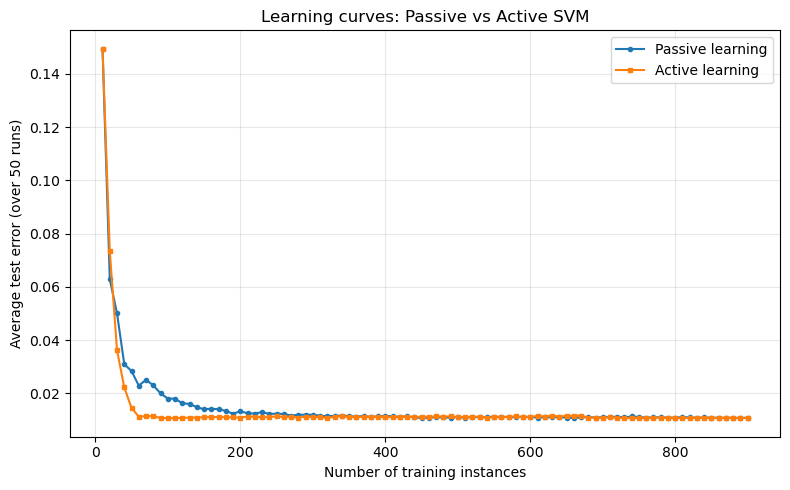

Error at selected training sizes:
  n= 10  passive=0.1494  active=0.1494  diff=+0.0000
  n= 50  passive=0.0284  active=0.0145  diff=-0.0139
  n=100  passive=0.0181  active=0.0107  diff=-0.0073
  n=200  passive=0.0133  active=0.0109  diff=-0.0024
  n=500  passive=0.0111  active=0.0111  diff=+0.0000
  n=900  passive=0.0109  active=0.0107  diff=-0.0002


In [38]:
errors_passive = np.load("errors_passive.npy")
errors_active  = np.load("errors_active.npy")

print("Passive shape:", errors_passive.shape)
print("Active  shape:", errors_active.shape)

sizes = np.arange(10, 901, 10)          

avg_passive = errors_passive.mean(axis=0)
avg_active  = errors_active.mean(axis=0)

plt.figure(figsize=(8, 5))
plt.plot(sizes, avg_passive, marker="o", markersize=3,
         label="Passive learning")
plt.plot(sizes, avg_active, marker="s", markersize=3,
         label="Active learning")
plt.xlabel("Number of training instances")
plt.ylabel("Average test error (over 50 runs)")
plt.title("Learning curves: Passive vs Active SVM")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Error at selected training sizes:")
for n in [10, 50, 100, 200, 500, 900]:
    i = n // 10 - 1
    print(f"  n={n:3d}  passive={avg_passive[i]:.4f}  "
          f"active={avg_active[i]:.4f}  "
          f"diff={avg_active[i] - avg_passive[i]:+.4f}")
np.save("avg_passive.npy", avg_passive)
np.save("avg_active.npy",  avg_active)

Active learning achieved lower average test errors than passive learning at the reported training sizes of 50, 100, and 200 samples. At 50 samples, the errors were 0.0145 and 0.0284, respectively; at 100 samples, they were 0.0107 and 0.0181. This suggests that selecting samples near the decision boundary improved label efficiency. As the training size increased, the difference narrowed, and both methods approached a test error of approximately 0.011. Active learning therefore provided its main benefit with a limited labeling budget.